In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

In [3]:
train = pd.read_csv("C:\\imp stuff\\credit car fraou\\data\\train.csv")
X = train.drop(columns=["Class"])
y = train["Class"]

# Split the training data again: 75% to learn from (fit), 25% to score on (val)
X_fit, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print(f"Learn from: {len(X_fit):,} rows, {y_fit.sum()} frauds")
print(f"Score on:   {len(X_val):,} rows, {y_val.sum()} frauds")

Learn from: 170,235 rows, 284 frauds
Score on:   56,745 rows, 94 frauds


In [4]:
# A list that will collect one row of results per model, and a dict to keep each model's probabilities
results = []
probs = {}


def evaluate(name, y_true, prob):
    # Save the probabilities so we can draw all the PR curves together at the end
    probs[name] = prob

    # Overall quality across all thresholds
    pr_auc = average_precision_score(y_true, prob)

    # Precision and recall at every possible threshold
    prec, rec, thr = precision_recall_curve(y_true, prob)

    # F1 for each threshold. The last precision/recall point has no threshold, so [:-1] drops it.
    # The tiny 1e-12 avoids dividing by zero.
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)

    # np.argmax gives the position of the highest F1
    best = np.argmax(f1)

    row = {
        "Model": name,
        "PR-AUC": pr_auc,
        "Best threshold": thr[best],
        "Precision": prec[best],
        "Recall": rec[best],
        "F1": f1[best],
    }
    results.append(row)

    # Print a one-line summary so you can see the result straight away
    print(f"{name}: PR-AUC {pr_auc:.3f} | best threshold {thr[best]:.3f} | "
          f"precision {prec[best]:.3f} | recall {rec[best]:.3f}")

In [5]:
base = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
base.fit(X_fit, y_fit)

# predict_proba gives [prob legit, prob fraud]; [:, 1] keeps the fraud probability
base_prob = base.predict_proba(X_val)[:, 1]

evaluate("Logistic (balanced)", y_val, base_prob)

Logistic (balanced): PR-AUC 0.787 | best threshold 1.000 | precision 0.875 | recall 0.819


In [6]:
# Thresholds to try in the table
thresholds_to_try = [0.5, 0.7, 0.9, 0.95, 0.99]
y_arr = y_val.values   # plain array version of the answers, easier to do maths with

rows = []
for t in thresholds_to_try:
    pred = (base_prob >= t)                       # True where we flag fraud
    tp = ((pred == 1) & (y_arr == 1)).sum()       # fraud correctly flagged
    fp = ((pred == 1) & (y_arr == 0)).sum()       # legit wrongly flagged
    fn = ((pred == 0) & (y_arr == 1)).sum()       # fraud missed
    rows.append({
        "Threshold": t,
        "Frauds caught": tp,
        "Frauds missed": fn,
        "False alarms": fp,
        "Precision": tp / max(tp + fp, 1),        # max(..., 1) avoids dividing by zero
        "Recall": tp / (tp + fn),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

 Threshold  Frauds caught  Frauds missed  False alarms  Precision  Recall
      0.50             85              9          1494      0.054   0.904
      0.70             85              9           742      0.103   0.904
      0.90             83             11           253      0.247   0.883
      0.95             83             11           134      0.382   0.883
      0.99             81             13            58      0.583   0.862


Lowest-cost threshold: 0.98  (total cost 1,248)
Cost at the default 0.5: 3,888


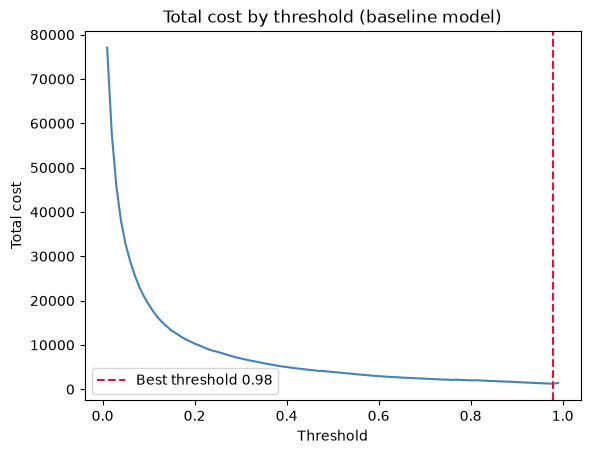

In [7]:
# ---- Cost-based threshold (EDIT THESE: they are example numbers, not real data) ----
COST_MISSED_FRAUD = 100   # what one missed fraud costs
COST_FALSE_ALARM = 2      # what one false alarm costs (review time, customer friction)

grid = np.linspace(0.01, 0.99, 99)   # 99 thresholds from 0.01 to 0.99
costs = []
for t in grid:
    pred = (base_prob >= t)
    fp = ((pred == 1) & (y_arr == 0)).sum()
    fn = ((pred == 0) & (y_arr == 1)).sum()
    costs.append(fn * COST_MISSED_FRAUD + fp * COST_FALSE_ALARM)

best_t = grid[int(np.argmin(costs))]   # the threshold with the lowest total cost
print(f"Lowest-cost threshold: {best_t:.2f}  (total cost {min(costs):,})")
print(f"Cost at the default 0.5: {costs[49]:,}")

plt.plot(grid, costs, color="steelblue")
plt.axvline(best_t, color="crimson", linestyle="--", label=f"Best threshold {best_t:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Total cost")
plt.title("Total cost by threshold (baseline model)")
plt.legend()
plt.show()

In [8]:
# fit_resample makes the extra fraud rows and returns the new, balanced X and y
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X_fit, y_fit)

print("Before SMOTE: frauds =", y_fit.sum(), "of", len(y_fit))
print("After SMOTE:  frauds =", y_smote.sum(), "of", len(y_smote))

# Train a plain Logistic Regression on the balanced data
smote_model = LogisticRegression(max_iter=1000, random_state=42)
smote_model.fit(X_smote, y_smote)

# Score on the ORIGINAL validation set (not resampled)
smote_prob = smote_model.predict_proba(X_val)[:, 1]
evaluate("Logistic + SMOTE", y_val, smote_prob)

Before SMOTE: frauds = 284 of 170235
After SMOTE:  frauds = 169951 of 339902
Logistic + SMOTE: PR-AUC 0.787 | best threshold 1.000 | precision 0.875 | recall 0.819


In [9]:
under = RandomUnderSampler(random_state=42)
X_under, y_under = under.fit_resample(X_fit, y_fit)

print("Rows after undersampling:", len(y_under), "(frauds:", y_under.sum(), ")")

under_model = LogisticRegression(max_iter=1000, random_state=42)
under_model.fit(X_under, y_under)

under_prob = under_model.predict_proba(X_val)[:, 1]
evaluate("Logistic + Undersampling", y_val, under_prob)

Rows after undersampling: 568 (frauds: 284 )
Logistic + Undersampling: PR-AUC 0.490 | best threshold 1.000 | precision 0.563 | recall 0.521


In [10]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=3,                  # each leaf must have at least 3 rows (avoids tiny, noisy rules)
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_fit, y_fit)

rf_prob = rf.predict_proba(X_val)[:, 1]
evaluate("Random Forest", y_val, rf_prob)

Random Forest: PR-AUC 0.862 | best threshold 0.629 | precision 0.908 | recall 0.840


In [11]:
# How many legit rows there are for every fraud row
ratio = (y_fit == 0).sum() / (y_fit == 1).sum()

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=ratio,
    eval_metric="aucpr",       # tell XGBoost to judge itself on PR-AUC
    tree_method="hist",        # a fast way of building trees
    n_jobs=-1,
    random_state=42,
)
xgb.fit(X_fit, y_fit)

xgb_prob = xgb.predict_proba(X_val)[:, 1]
evaluate("XGBoost", y_val, xgb_prob)

XGBoost: PR-AUC 0.882 | best threshold 0.996 | precision 0.963 | recall 0.819


                          PR-AUC  Best threshold  Precision  Recall     F1
Model                                                                     
XGBoost                    0.882           0.996      0.962   0.819  0.885
Random Forest              0.862           0.629      0.908   0.840  0.873
Logistic + SMOTE           0.787           1.000      0.875   0.819  0.846
Logistic (balanced)        0.787           1.000      0.875   0.819  0.846
Logistic + Undersampling   0.490           1.000      0.563   0.521  0.541


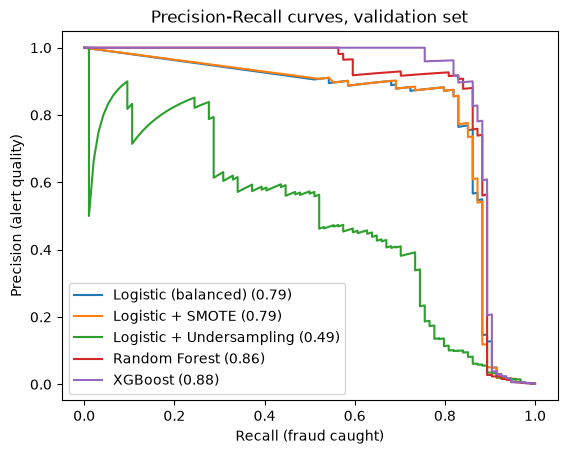

In [12]:
table = pd.DataFrame(results).set_index("Model").sort_values("PR-AUC", ascending=False)
print(table.round(3))

# Draw every model's precision-recall curve on the same chart
for name, p in probs.items():
    prec, rec, _ = precision_recall_curve(y_val, p)
    plt.plot(rec, prec, label=f"{name} ({average_precision_score(y_val, p):.2f})")

plt.xlabel("Recall (fraud caught)")
plt.ylabel("Precision (alert quality)")
plt.title("Precision-Recall curves, validation set")
plt.legend()
plt.show()